# Fair Model Comparison for FD001 RUL

This notebook summarizes the existing controlled comparison of Ridge, SimpleRNN, and LSTM models. It reads saved metrics and predictions only; it does not train models or write results.

In [1]:
import ast
import itertools
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()
while not (project_root / "reports" / "fd001_fair_comparison.csv").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate reports/fd001_fair_comparison.csv")
    project_root = project_root.parent

metrics_path = project_root / "reports" / "fd001_fair_comparison.csv"
predictions_path = project_root / "reports" / "fd001_fair_comparison_predictions.csv"
fair_runs = pd.read_csv(metrics_path)
predictions = pd.read_csv(predictions_path)
required_metric_columns = {
    "model", "feature_representation", "pca_components", "window_length",
    "run_seed", "rmse", "mae", "nasa_score",
}
if not required_metric_columns.issubset(fair_runs.columns):
    raise ValueError("Fair comparison CSV is missing required metric columns")
if not {"unit_id", "official_RUL"}.issubset(predictions.columns):
    raise ValueError("Prediction CSV must contain unit_id and official_RUL")
if fair_runs[["model", "feature_representation", "window_length", "run_seed", "rmse", "mae", "nasa_score"]].isna().any().any():
    raise ValueError("Fair comparison model, run, or metric fields contain missing values")

expected_models = [
    "Original 14-sensor Ridge (retrained)",
    "PCA Ridge",
    "Original 14-sensor LSTM",
    "PCA SimpleRNN",
    "PCA LSTM",
]
if set(fair_runs["model"]) != set(expected_models):
    raise ValueError("Fair comparison CSV does not contain the expected five models")
if predictions["unit_id"].nunique() != len(predictions):
    raise ValueError("Prediction CSV contains duplicate test engine IDs")

# Read protocol constants as source text; do not import or execute the experiment script.
script_path = project_root / "scripts" / "audit_compare_fd001.py"
script_text = script_path.read_text(encoding="utf-8")
script_tree = ast.parse(script_text)
protocol_names = {"WINDOW", "RUL_CAP", "SPLIT_SEED", "MODEL_SEEDS"}
protocol = {}
for node in script_tree.body:
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Name) and target.id in protocol_names:
                protocol[target.id] = ast.literal_eval(node.value)
if set(protocol) != protocol_names:
    raise ValueError("Could not read all comparison protocol constants")
split_match = re.search(
    r"GroupShuffleSplit\(\s*n_splits=1,\s*test_size=([0-9.]+),\s*random_state=SPLIT_SEED,",
    script_text,
)
if split_match is None:
    raise ValueError("Could not verify the engine split settings in the script")
split_fraction = float(split_match.group(1))
uses_official_rul = (
    "OFFICIAL_RUL_PATH" in script_text
    and "calculate_metrics(official_rul, prediction" in script_text
)
if not uses_official_rul:
    raise ValueError("Could not verify official test RUL is used for metrics")

print(f"Metrics CSV rows: {len(fair_runs)}")
print(f"Metrics CSV columns: {fair_runs.columns.tolist()}")
print(f"Models: {fair_runs['model'].drop_duplicates().tolist()}")
print(f"Runs per model: {fair_runs.groupby('model', sort=False).size().to_dict()}")
print(f"Neural run seeds in CSV: {sorted(fair_runs.loc[fair_runs['run_seed'].astype(str).str.isnumeric(), 'run_seed'].astype(int).unique().tolist())}")
print(f"Engine split: {1-split_fraction:.0%}/{split_fraction:.0%} by unit_id; seed {protocol['SPLIT_SEED']}")
print(f"Window length: {protocol['WINDOW']}; training RUL cap: {protocol['RUL_CAP']}")
print(f"Neural seeds configured in source: {list(protocol['MODEL_SEEDS'])}")
print(f"Test target: official_RUL loaded from RUL_FD001.txt; metrics use official_rul without clipping: {uses_official_rul}")
print(f"Prediction rows and unique engines: {len(predictions)}, {predictions['unit_id'].nunique()}")

Metrics CSV rows: 11
Metrics CSV columns: ['model', 'feature_representation', 'pca_components', 'window_length', 'run_seed', 'rmse', 'mae', 'nasa_score']
Models: ['Original 14-sensor Ridge (retrained)', 'PCA Ridge', 'Original 14-sensor LSTM', 'PCA SimpleRNN', 'PCA LSTM']
Runs per model: {'Original 14-sensor Ridge (retrained)': 1, 'PCA Ridge': 1, 'Original 14-sensor LSTM': 3, 'PCA SimpleRNN': 3, 'PCA LSTM': 3}
Neural run seeds in CSV: [42, 43, 44]
Engine split: 80%/20% by unit_id; seed 42
Window length: 30; training RUL cap: 125
Neural seeds configured in source: [42, 43, 44]
Test target: official_RUL loaded from RUL_FD001.txt; metrics use official_rul without clipping: True
Prediction rows and unique engines: 100, 100


## Protocol and models

The verified split and evaluation settings are printed above from the comparison script; model inputs and run seeds are shown in the CSV-derived tables below. The pipeline groups engines by `unit_id`, fits each scaler and PCA using training-engine rows only, and evaluates one final window per test engine against the uncapped official RUL labels.

The five entries are a 14-sensor Ridge baseline, PCA Ridge, a 14-sensor LSTM, PCA SimpleRNN, and PCA LSTM. The PCA representation starts from 21 sensor columns and retains the saved component representation; sensor 6 is included in PCA but excluded from the 14-sensor baseline. Six input columns have zero variance, so counting all PCA input columns as informative would overstate dimensionality reduction.

## Metrics

RMSE is the square root of mean squared error; MAE is mean absolute error. The NASA score uses `d = predicted RUL - true RUL`: when `d < 0`, the penalty is `exp(-d/13) - 1`; when `d >= 0`, it is `exp(d/10) - 1`. Penalties are summed over test engines. Lower values are better for all three metrics.

In [2]:
metric_names = ["rmse", "mae", "nasa_score"]
summary = (
    fair_runs.groupby("model", sort=False)
    .agg(
        runs=("run_seed", "count"),
        rmse_mean=("rmse", "mean"), rmse_sd=("rmse", "std"),
        mae_mean=("mae", "mean"), mae_sd=("mae", "std"),
        nasa_score_mean=("nasa_score", "mean"), nasa_score_sd=("nasa_score", "std"),
    )
    .reindex(expected_models)
    .reset_index()
)

def mean_sd_text(mean, standard_deviation):
    if pd.isna(standard_deviation):
        return f"{mean:.4f} (single run; std n/a)"
    return f"{mean:.4f} ± {standard_deviation:.4f}"

display_model_names = {
    "Original 14-sensor Ridge (retrained)": "14-sensor Ridge",
    "Original 14-sensor LSTM": "14-sensor LSTM",
}
results_table = pd.DataFrame({"Model": summary["model"].replace(display_model_names), "Runs": summary["runs"]})
for metric, label in (("rmse", "RMSE"), ("mae", "MAE"), ("nasa_score", "NASA score")):
    results_table[label] = [
        mean_sd_text(row[f"{metric}_mean"], row[f"{metric}_sd"])
        for _, row in summary.iterrows()
    ]
print("Results: neural models show mean ± sample standard deviation (ddof=1); deterministic Ridge has no standard-deviation estimate.")
display(results_table)

Results: neural models show mean ± sample standard deviation (ddof=1); deterministic Ridge has no standard-deviation estimate.


,Model,Runs,RMSE,MAE,NASA score
0,14-sensor Ridge,1,21.6072 (single run; std n/a),17.3268 (single run; std n/a),1087.1635 (single run; std n/a)
1,PCA Ridge,1,21.7092 (single run; std n/a),17.4440 (single run; std n/a),1079.8589 (single run; std n/a)
2,14-sensor LSTM,3,14.8876 ± 0.1792,11.1554 ± 0.1757,380.3457 ± 13.2517
3,PCA SimpleRNN,3,19.1310 ± 1.1944,14.0696 ± 1.0689,988.6472 ± 227.4474
4,PCA LSTM,3,15.4767 ± 0.6264,11.7092 ± 0.2079,494.5570 ± 159.9626


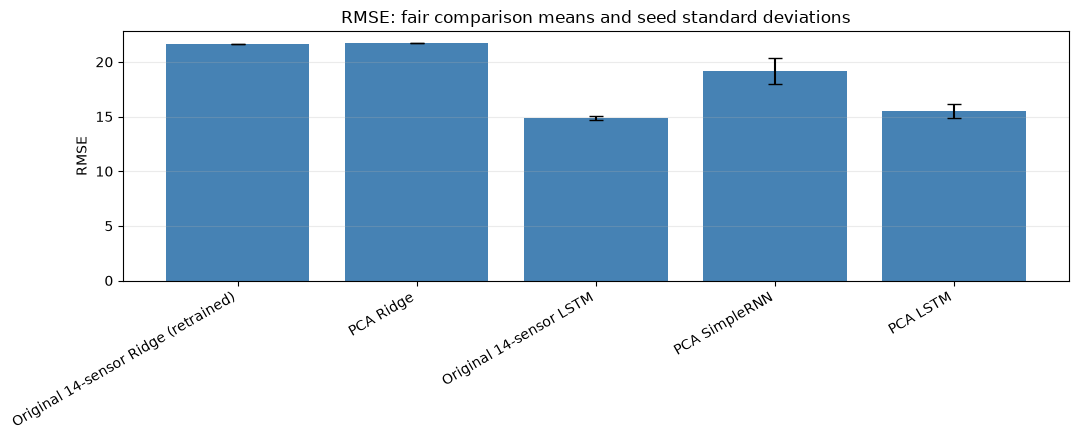

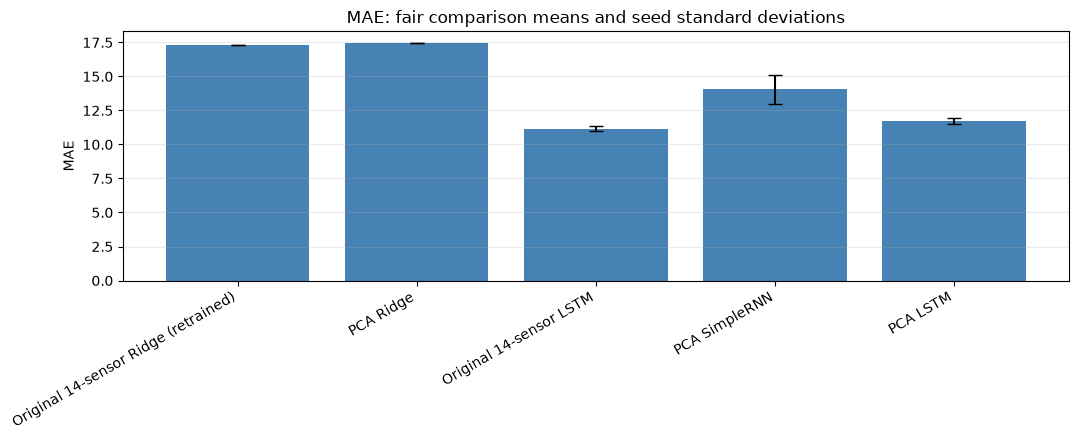

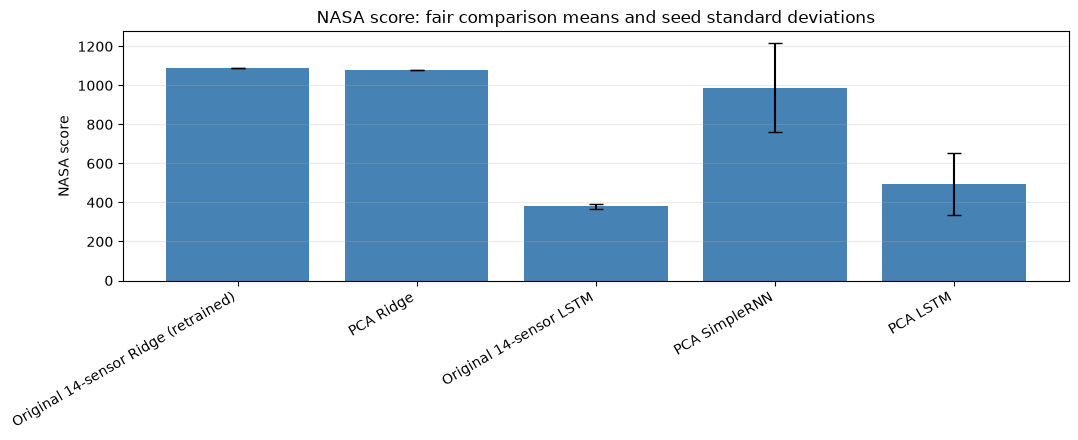

In [3]:
for metric, mean_column, sd_column, label in (
    ("rmse", "rmse_mean", "rmse_sd", "RMSE"),
    ("mae", "mae_mean", "mae_sd", "MAE"),
    ("nasa_score", "nasa_score_mean", "nasa_score_sd", "NASA score"),
):
    means = summary[mean_column].to_numpy(dtype=float)
    errors = summary[sd_column].fillna(0).to_numpy(dtype=float)
    figure, axis = plt.subplots(figsize=(11, 4.5))
    axis.bar(np.arange(len(summary)), means, yerr=errors, capsize=5, color="steelblue")
    axis.set_xticks(np.arange(len(summary)), summary["model"], rotation=30, ha="right")
    axis.set_ylabel(label)
    axis.set_title(f"{label}: fair comparison means and seed standard deviations")
    axis.grid(axis="y", alpha=0.25)
    figure.tight_layout()
    plt.show()
    plt.close(figure)

In [4]:
print("Per-seed and deterministic single-run metrics from the CSV:")
display(
    fair_runs[[
        "model", "feature_representation", "pca_components", "window_length",
        "run_seed", "rmse", "mae", "nasa_score",
    ]]
)

Per-seed and deterministic single-run metrics from the CSV:


,model,feature_representation,pca_components,window_length,run_seed,rmse,mae,nasa_score
0,Original 14-sensor Ridge (retrained),14 selected sensors + MinMaxScaler,NaN,30,deterministic,21.607243,17.326797,1087.163494
1,PCA Ridge,21 sensors -> StandardScaler -> PCA,10.0,30,deterministic,21.709157,17.444019,1079.858901
2,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,42,14.993410,11.069129,386.341491
3,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,43,14.680767,11.039498,389.539858
4,Original 14-sensor LSTM,14 selected sensors + MinMaxScaler,NaN,30,44,14.988765,11.357522,365.155819
5,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,42,20.116518,15.052484,1141.145388
6,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,43,19.473842,14.224621,1097.575168
7,PCA SimpleRNN,21 sensors -> StandardScaler -> PCA,10.0,30,44,17.802772,12.931655,727.220949
8,PCA LSTM,21 sensors -> StandardScaler -> PCA,10.0,30,42,14.781389,11.520009,358.552438
9,PCA LSTM,21 sensors -> StandardScaler -> PCA,10.0,30,43,15.996947,11.675745,670.795667


In [5]:
print("Pairwise interpretation of the CSV-derived means:")
print("For neural models, a mean gap must exceed both models' sample standard deviations to be called clearly larger than seed spread.")
print("Otherwise the result is reported as: no clear difference at 3 seeds.")
for metric, label in (("rmse", "RMSE"), ("mae", "MAE"), ("nasa_score", "NASA score")):
    print(f"\n{label} (lower is better)")
    for left, right in itertools.combinations(summary.to_dict("records"), 2):
        left_sd = left[f"{metric}_sd"]
        right_sd = right[f"{metric}_sd"]
        if pd.isna(left_sd) or pd.isna(right_sd):
            print(
                f"{left['model']} vs {right['model']}: no clear difference at 3 seeds; "
                "Ridge has one deterministic run and no variance estimate."
            )
            continue
        gap = abs(left[f"{metric}_mean"] - right[f"{metric}_mean"])
        spread = max(left_sd, right_sd)
        if gap > spread:
            lower = left if left[f"{metric}_mean"] < right[f"{metric}_mean"] else right
            print(
                f"{lower['model']} has the lower mean; the mean gap ({gap:.4f}) "
                f"exceeds both seed standard deviations (largest: {spread:.4f})."
            )
        else:
            print(f"{left['model']} vs {right['model']}: no clear difference at 3 seeds.")

Pairwise interpretation of the CSV-derived means:
For neural models, a mean gap must exceed both models' sample standard deviations to be called clearly larger than seed spread.
Otherwise the result is reported as: no clear difference at 3 seeds.

RMSE (lower is better)
Original 14-sensor Ridge (retrained) vs PCA Ridge: no clear difference at 3 seeds; Ridge has one deterministic run and no variance estimate.
Original 14-sensor Ridge (retrained) vs Original 14-sensor LSTM: no clear difference at 3 seeds; Ridge has one deterministic run and no variance estimate.
Original 14-sensor Ridge (retrained) vs PCA SimpleRNN: no clear difference at 3 seeds; Ridge has one deterministic run and no variance estimate.
Original 14-sensor Ridge (retrained) vs PCA LSTM: no clear difference at 3 seeds; Ridge has one deterministic run and no variance estimate.
PCA Ridge vs Original 14-sensor LSTM: no clear difference at 3 seeds; Ridge has one deterministic run and no variance estimate.
PCA Ridge vs PCA Sim

In [6]:
prediction_columns = {
    "Original 14-sensor Ridge (retrained)": lambda seed: "original_14sensor_ridge",
    "PCA Ridge": lambda seed: "pca_ridge",
    "Original 14-sensor LSTM": lambda seed: f"original_14sensor_lstm_seed{seed}",
    "PCA SimpleRNN": lambda seed: f"pca_simplernn_seed{seed}",
    "PCA LSTM": lambda seed: f"pca_lstm_seed{seed}",
}
required_prediction_columns = {"unit_id", "official_RUL"}
for _, row in fair_runs.iterrows():
    required_prediction_columns.add(prediction_columns[row["model"]](str(row["run_seed"])))
missing_prediction_columns = required_prediction_columns - set(predictions.columns)
if missing_prediction_columns:
    raise ValueError(f"Prediction CSV is missing columns: {sorted(missing_prediction_columns)}")
if not predictions["official_RUL"].between(0, np.inf).all():
    raise ValueError("Official RUL values must be nonnegative for bucket analysis")

above_125_count = int((predictions["official_RUL"] > 125).sum())
minimum_high_bucket_count = 10
if above_125_count >= minimum_high_bucket_count:
    bucket_edges = [-np.inf, 30, 70, 125, np.inf]
    bucket_labels = ["0-30", "30-70", "70-125", "125+"]
    interval_text = "(-∞, 30], (30, 70], (70, 125], (125, ∞)"
else:
    bucket_edges = [-np.inf, 30, 70, np.inf]
    bucket_labels = ["0-30", "30-70", "70+"]
    interval_text = "(-∞, 30], (30, 70], (70, ∞)"
predictions = predictions.copy()
predictions["rul_bucket"] = pd.cut(
    predictions["official_RUL"],
    bins=bucket_edges,
    labels=bucket_labels,
    right=True,
    include_lowest=True,
)

print("Engine counts by true-RUL bucket (shown before bucket metrics):")
bucket_counts = (
    predictions["rul_bucket"]
    .value_counts(sort=False)
    .reindex(bucket_labels, fill_value=0)
    .rename_axis("true_RUL_bucket")
    .reset_index(name="engine_count")
)
display(bucket_counts)
print(f"Interval convention: {interval_text}; the upper edge is included except for the open-ended final bucket.")
print(f"Separate high-RUL bucket rule: split above 125 only when that bucket has at least {minimum_high_bucket_count} engines; observed count: {above_125_count}.")
print("RUL above the training cap can have structural error because capped-target models cannot learn target values above the cap; small buckets are noisy.")

bucket_rows = []
for _, run in fair_runs.iterrows():
    prediction_column = prediction_columns[run["model"]](str(run["run_seed"]))
    for bucket in bucket_labels:
        group = predictions.loc[predictions["rul_bucket"] == bucket]
        if group.empty:
            bucket_rows.append({
                "model": run["model"], "run_seed": run["run_seed"],
                "true_RUL_bucket": bucket, "engine_count": 0,
                "rmse": np.nan, "late_prediction_share": np.nan,
            })
            continue
        truth = group["official_RUL"].to_numpy(dtype=float)
        predicted = group[prediction_column].to_numpy(dtype=float)
        bucket_rows.append({
            "model": run["model"], "run_seed": run["run_seed"],
            "true_RUL_bucket": bucket, "engine_count": len(group),
            "rmse": float(np.sqrt(np.mean((predicted - truth) ** 2))),
            "late_prediction_share": float(np.mean(predicted > truth)),
        })
bucket_metrics = pd.DataFrame(bucket_rows)
print("Bucket RMSE and fraction of predictions later than true RUL, by run:")
display(bucket_metrics)

Engine counts by true-RUL bucket (shown before bucket metrics):


,true_RUL_bucket,engine_count
0,0-30,25
1,30-70,17
2,70-125,47
3,125+,11


Interval convention: (-∞, 30], (30, 70], (70, 125], (125, ∞); the upper edge is included except for the open-ended final bucket.
Separate high-RUL bucket rule: split above 125 only when that bucket has at least 10 engines; observed count: 11.
RUL above the training cap can have structural error because capped-target models cannot learn target values above the cap; small buckets are noisy.
Bucket RMSE and fraction of predictions later than true RUL, by run:


,model,run_seed,true_RUL_bucket,engine_count,rmse,late_prediction_share
0,Original 14-sensor Ridge (retrained),deterministic,0-30,25,22.228581,0.880000
1,Original 14-sensor Ridge (retrained),deterministic,30-70,17,20.970985,1.000000
2,Original 14-sensor Ridge (retrained),deterministic,70-125,47,18.556575,0.340426
3,Original 14-sensor Ridge (retrained),deterministic,125+,11,31.150611,0.090909
4,PCA Ridge,deterministic,0-30,25,22.007173,0.880000
5,PCA Ridge,deterministic,30-70,17,20.925141,1.000000
6,PCA Ridge,deterministic,70-125,47,18.614349,0.340426
7,PCA Ridge,deterministic,125+,11,32.039741,0.000000
8,Original 14-sensor LSTM,42,0-30,25,3.847879,0.720000
9,Original 14-sensor LSTM,42,30-70,17,16.424834,0.705882


## Limitations

- The experiment covers FD001 simulated data, one fault mode, one operating condition, and the test engines represented in the prediction file.
- It uses one fixed engine split and a fixed window length. PCA and 14-sensor inputs differ; PCA includes sensor 6, while the baseline does not. Six PCA input columns have zero variance.
- Neural-model seed spread covers training-seed variance only. The split seed stays fixed, so the standard deviation does not measure split variance. Ridge has one deterministic run and no variance estimate.
- The shortest test engine has 31 cycles; 0 of the 100 engines have fewer than 30 cycles. The script handles any shorter engine by left-padding with repeated copies of its first sensor row before taking the final 30-cycle window.
- SimpleRNN was evaluated only with PCA input; the RNN-versus-LSTM comparison therefore holds under PCA input only.
- Notebook 01 has a scaler-leakage issue: it fits scaling before its later engine split. Those exploratory results are not used in this comparison.
- Published results, including Ramasso and Saxena, may use different data splits, targets, preprocessing, or scoring protocols and are not directly comparable without harmonization.
- Bucket metrics can be noisy when a bucket has few engines. Training targets are capped, so errors for true RUL above the cap are partly structural.

In [7]:
print("Conclusion from the fair-comparison CSV:")
for metric, label in (("rmse", "RMSE"), ("mae", "MAE"), ("nasa_score", "NASA score")):
    row = summary.loc[summary[f"{metric}_mean"].idxmin()]
    print(f"The lowest mean {label} is for {row['model']} ({mean_sd_text(row[f'{metric}_mean'], row[f'{metric}_sd'])}).")
print("These are descriptive results from this saved comparison, not a claim of universal superiority.")
print("For neural models, interpret mean gaps against the displayed sample standard deviations; the deterministic Ridge runs have no variance estimate.")
print("The optional bucket table shows how prediction errors vary across the official test RUL ranges represented in the saved predictions.")

Conclusion from the fair-comparison CSV:
The lowest mean RMSE is for Original 14-sensor LSTM (14.8876 ± 0.1792).
The lowest mean MAE is for Original 14-sensor LSTM (11.1554 ± 0.1757).
The lowest mean NASA score is for Original 14-sensor LSTM (380.3457 ± 13.2517).
These are descriptive results from this saved comparison, not a claim of universal superiority.
For neural models, interpret mean gaps against the displayed sample standard deviations; the deterministic Ridge runs have no variance estimate.
The optional bucket table shows how prediction errors vary across the official test RUL ranges represented in the saved predictions.


## References

- Saxena et al. (2008), PHM08 damage propagation modelling.
- Heimes (2008), recurrent neural networks for remaining useful life estimation.
- Zheng et al. (2017), LSTM-based remaining useful life estimation.
- Babu et al. (2016), deep convolutional approaches to remaining useful life estimation.
- Ramasso and Saxena, *International Journal of Prognostics and Health Management* (IJPHM).